In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import platform
fonts = {"Windows": "Malgun Gothic", "Darwin": "AppleGothic"}
plt.rcParams["font.family"] = fonts.get(platform.system(), "NanumGothic")
plt.rcParams["axes.unicode_minus"] = False

In [2]:
df = pd.read_csv("sales_data.csv")
dates = ["order_date", "shipping_date", "delivery_date"]
for col in dates:
    df[col] = pd.to_datetime(df[col])
df.shape

(1030, 14)

In [3]:
before = len(df)
df = df.drop_duplicates()
print(before, "->", len(df))

1030 -> 1004


In [4]:
bad = df["quantity"] > 100
df.loc[bad, "quantity"] = (df.loc[bad, "total_sales"] / df.loc[bad, "unit_price"]).round().astype(int)
diff = (df["total_sales"] - df["quantity"] * df["unit_price"]).abs()
print("고친 줄 :", bad.sum(), " 수량 최대 :", df["quantity"].max(), " 총액 안 맞는 줄 :", (diff > 1).sum())

고친 줄 : 22  수량 최대 : 99  총액 안 맞는 줄 : 0


In [5]:
df["date_error"] = df["delivery_date"] < df["shipping_date"]
print("date_error :", df["date_error"].sum(), "건")
df.to_csv("sales_clean.csv", index=False)
df.shape

date_error : 147 건


(1004, 15)

## Q1. 배송 기간(도착일 − 배송일)은 보통 며칠인가

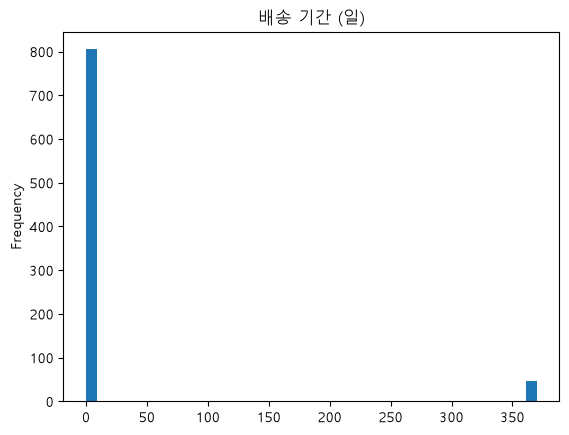

평균 : 22.1  중앙값 : 2.0


In [6]:
ok = df[df["date_error"] == False]
days = (ok["delivery_date"] - ok["shipping_date"]).dt.days
days.plot.hist(bins=40, title="배송 기간 (일)")
plt.show()
print("평균 :", round(days.mean(), 1), " 중앙값 :", days.median())

In [7]:
print("300일 넘는 줄 :", (days > 300).sum())
print(days[days > 300].describe())

300일 넘는 줄 : 47
count     47.000000
mean     366.638298
std        1.798859
min      364.000000
25%      365.000000
50%      367.000000
75%      368.000000
max      370.000000
dtype: float64


In [8]:
ok.loc[days > 300, ["order_date", "shipping_date", "delivery_date"]].head()

,order_date,shipping_date,delivery_date
11,2023-01-12,2023-01-15,2024-01-15
20,2023-01-21,2023-01-23,2024-01-27
29,2023-01-30,2023-02-03,2024-02-03
41,2023-02-11,2023-02-14,2024-02-17
68,2023-03-10,2023-03-14,2024-03-12


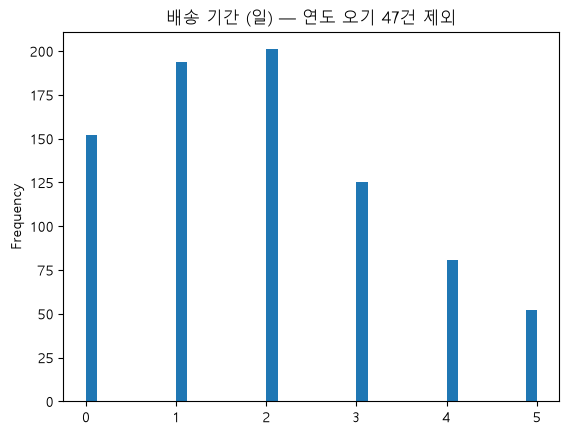

제외 후 평균 : 1.9  중앙값 : 2.0  건수 : 805


In [9]:
clean_days = days[days <= 300]
clean_days.plot.hist(bins=40, title="배송 기간 (일) — 연도 오기 47건 제외")
plt.show()
print("제외 후 평균 :", round(clean_days.mean(), 1), " 중앙값 :", clean_days.median(), " 건수 :", len(clean_days))

### Q1 답

- 배송 기간은 보통 **2일**이다(제외 후 805건, 중앙값 2.0일·평균 1.9일). 제외 전에는 평균 22.1일·중앙값 2.0일로 11배 차이가 났는데, 평균만 극단값에 끌려가기 때문이며 덩어리를 빼자 평균 1.9일 ≈ 중앙값 2.0일로 좁혀졌다.
- 오른쪽 끝 덩어리는 **364~370일에 몰린 47건**(표준편차 1.8일)으로, `2023-01-15 → 2024-01-15`처럼 월·일은 같고 도착일 연도만 1년 뒤였다. 실제 지연이라면 기간이 제각각이어야 하므로 **연도 입력 오류**로 판단했고, 실제 도착일을 알 수 없어 복원하지 않고 **제외**했다(1차시 날짜 역전 147건과 같은 기준).

## Q2. 만족도가 낮을수록 반품이 많은가

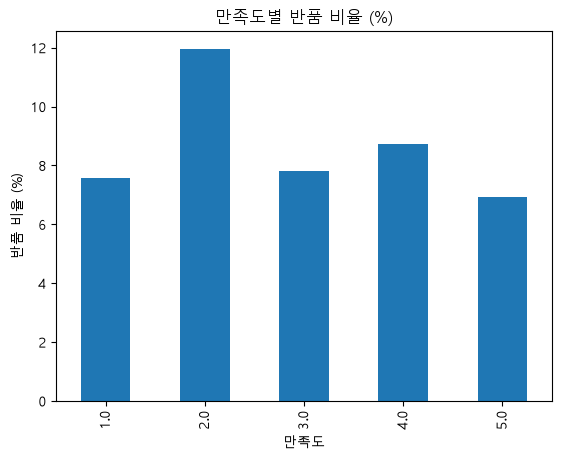

satisfaction
1.0     7.6
2.0    12.0
3.0     7.8
4.0     8.7
5.0     6.9
Name: status, dtype: float64


In [10]:
returned = df["status"] == "반품"
by_sat = returned.groupby(df["satisfaction"]).mean() * 100
by_sat.plot.bar(title="만족도별 반품 비율 (%)")
plt.xlabel("만족도")
plt.ylabel("반품 비율 (%)")
plt.show()
print(by_sat.round(1))

In [11]:
print(df["satisfaction"].value_counts().sort_index())

satisfaction
1.0    224
2.0    184
3.0    192
4.0    172
5.0    202
Name: count, dtype: int64


### Q2 답

- **아니다.** 만족도 1~5의 반품 비율은 7.6% / 12.0% / 7.8% / 8.7% / 6.9%로 단조 감소 경향이 없다. 가장 불만족인 1점(7.6%)이 2점(12.0%)보다 낮고, 3점(7.8%) → 4점(8.7%)에서도 다시 올라간다.
- 각 만족도의 표본은 172~224건으로 고르게 분포하므로 특정 구간이 표본 부족으로 튄 것이 아니며, 최고(2점, 12.0%)와 최저(5점, 6.9%)의 차이도 5.1%p에 그친다. 만족도는 반품 여부를 설명하는 변수로 보기 어렵다.

## Q3. 카테고리 매출 1위의 이유는 건수·단가·수량 중 무엇인가

In [12]:
by_cat = df.groupby("category").agg({
    "total_sales": ["count", "sum"],
    "unit_price": "mean",
    "quantity": "mean"
}).round(1)
by_cat = by_cat.sort_values(("total_sales", "sum"), ascending=False)
by_cat

total_sales               unit_price quantity
               count           sum       mean     mean
category                                              
가구               213  2.843337e+09   257322.9     51.0
식품               210  2.513274e+09   255232.9     47.3
전자제품             207  2.471628e+09   249651.6     48.0
도서               204  2.453240e+09   238500.6     49.5
의류               170  2.181904e+09   249447.2     51.6

### Q3 답

- 매출 1위는 가구(28.4억)이며, 주된 이유는 **건수**다. 가구는 건수 213건으로 최다, 평균단가 257,323원으로 최고지만 평균수량 51.0개는 1위가 아니다(의류 51.6개가 더 높다). 5위 의류와 비교하면 매출 차이 30.3% 중 건수 차이가 25.3%p를 차지하고 단가는 3.2%, 수량은 오히려 −1.2%다.
- 다만 상위 4개 카테고리의 건수는 204~213건으로 거의 같아 매출 차이도 24.5~28.4억에 그치며, 카테고리 간 격차 자체가 크지 않다. 의류만 건수 170건으로 뒤처지면서 최하위가 되었다.